In [89]:
import pandas as pd
import matplotlib.pylab as plt
import numpy as np
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import train_test_split

In [60]:
df = pd.read_csv("Melbourne_housing_FULL.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         34857 non-null  object 
 1   Address        34857 non-null  object 
 2   Rooms          34857 non-null  int64  
 3   Type           34857 non-null  object 
 4   Price          27247 non-null  float64
 5   Method         34857 non-null  object 
 6   SellerG        34857 non-null  object 
 7   Date           34857 non-null  object 
 8   Distance       34856 non-null  float64
 9   Postcode       34856 non-null  float64
 10  Bedroom2       26640 non-null  float64
 11  Bathroom       26631 non-null  float64
 12  Car            26129 non-null  float64
 13  Landsize       23047 non-null  float64
 14  BuildingArea   13742 non-null  float64
 15  YearBuilt      15551 non-null  float64
 16  CouncilArea    34854 non-null  object 
 17  Lattitude      26881 non-null  float64
 18  Longti

In [24]:
df.head(5)

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.5,3067.0,...,1.0,1.0,126.0,NaN,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0
1,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra City Council,-37.7996,144.9984,Northern Metropolitan,4019.0
2,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra City Council,-37.8079,144.9934,Northern Metropolitan,4019.0
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.5,3067.0,...,2.0,1.0,0.0,NaN,NaN,Yarra City Council,-37.8114,145.0116,Northern Metropolitan,4019.0
4,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra City Council,-37.8093,144.9944,Northern Metropolitan,4019.0


In [77]:
df.head(5)

,Rooms,Type,Price,Method,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,Lattitude,Longtitude,Regionname,Propertycount
1,2,h,1480000.0,S,2.5,2.0,1.0,1.0,202.0,160.2564,-37.7996,144.9984,Northern Metropolitan,4019.0
2,2,h,1035000.0,S,2.5,2.0,1.0,0.0,156.0,79.0000,-37.8079,144.9934,Northern Metropolitan,4019.0
4,3,h,1465000.0,SP,2.5,3.0,2.0,0.0,134.0,150.0000,-37.8093,144.9944,Northern Metropolitan,4019.0
5,3,h,850000.0,PI,2.5,3.0,2.0,1.0,94.0,160.2564,-37.7969,144.9969,Northern Metropolitan,4019.0
6,4,h,1600000.0,VB,2.5,3.0,1.0,2.0,120.0,142.0000,-37.8072,144.9941,Northern Metropolitan,4019.0


In [82]:
df['Regionname'].value_counts()

Regionname
Southern Metropolitan         6420
Northern Metropolitan         5993
Western Metropolitan          4622
Eastern Metropolitan          2558
South-Eastern Metropolitan    1029
Northern Victoria              142
Eastern Victoria               141
Western Victoria                88
Name: count, dtype: int64

In [61]:
df.drop(['Address','Suburb','SellerG','Date','Postcode','YearBuilt','CouncilArea'],axis=1,inplace=True)
# there are 9 methods
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Rooms          34857 non-null  int64  
 1   Type           34857 non-null  object 
 2   Price          27247 non-null  float64
 3   Method         34857 non-null  object 
 4   Distance       34856 non-null  float64
 5   Bedroom2       26640 non-null  float64
 6   Bathroom       26631 non-null  float64
 7   Car            26129 non-null  float64
 8   Landsize       23047 non-null  float64
 9   BuildingArea   13742 non-null  float64
 10  Lattitude      26881 non-null  float64
 11  Longtitude     26881 non-null  float64
 12  Regionname     34854 non-null  object 
 13  Propertycount  34854 non-null  float64
dtypes: float64(10), int64(1), object(3)
memory usage: 3.7+ MB


In [69]:
df.isna().sum()

Rooms               0
Type                0
Price            7610
Method              0
Distance            1
Bedroom2            0
Bathroom            0
Car                 0
Landsize            0
BuildingArea        0
Lattitude        7976
Longtitude       7976
Regionname          3
Propertycount       0
dtype: int64

In [66]:
col_to_zero = ['Bedroom2','Bathroom','Car','Propertycount']
df[col_to_zero] = df[col_to_zero].fillna(0)
col_to_mean = ['Landsize', 'BuildingArea']
df[col_to_mean] = df[col_to_mean].fillna(df[col_to_mean].mean())
# for i in col_to_mean:
    

In [85]:
df = pd.get_dummies(df, drop_first=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20993 entries, 1 to 34856
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Rooms                                  20993 non-null  int64  
 1   Price                                  20993 non-null  float64
 2   Distance                               20993 non-null  float64
 3   Bedroom2                               20993 non-null  float64
 4   Bathroom                               20993 non-null  float64
 5   Car                                    20993 non-null  float64
 6   Landsize                               20993 non-null  float64
 7   BuildingArea                           20993 non-null  float64
 8   Lattitude                              20993 non-null  float64
 9   Longtitude                             20993 non-null  float64
 10  Propertycount                          20993 non-null  float64
 11  Type_t 

## step 2:

<Axes: >

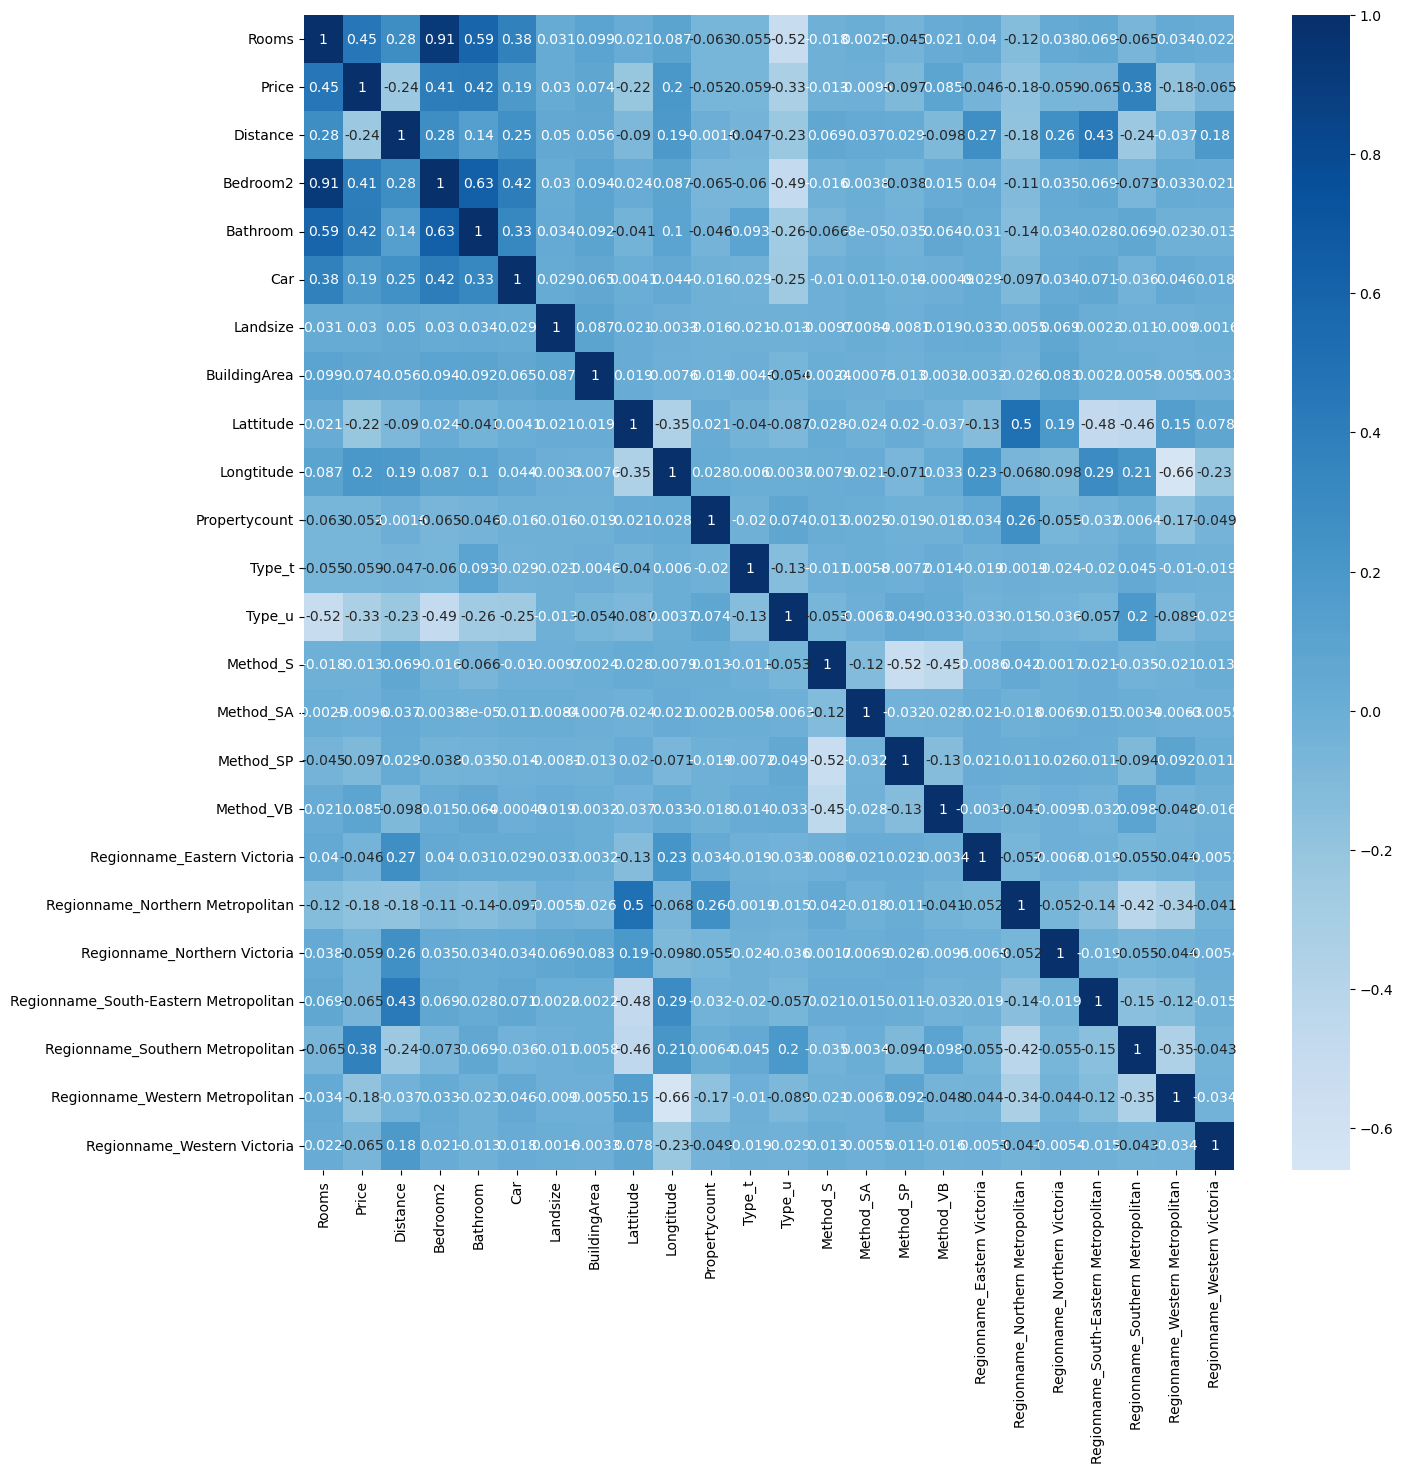

In [87]:
# Calculate correlation matrix
corr_matrix = df.corr( numeric_only=True)

# Create visualization
plt.figure(figsize=(15, 15))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, 
            annot=True,
            center=0,
            cmap='Blues'
)

In [88]:
X = df.drop('Price', axis =1)
y = df.Price

In [91]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

In [99]:
linear_m = LinearRegression()
las_m = Lasso(alpha=50,max_iter=100, tol = 0.1)
rid_m = Ridge(alpha=50, max_iter=100, tol = 0.1)
linear_m.fit(X_train,y_train)
las_m.fit(X_train,y_train)
rid_m.fit(X_train,y_train)

,alpha,50
,fit_intercept,True
,copy_X,True
,max_iter,100
,tol,0.1
,solver,'auto'
,positive,False
,random_state,None


In [100]:
print("score")
print("LinearRegression in test: ", linear_m.score(X_test,y_test))
print("LinearRegression in train: ", linear_m.score(X_train,y_train))
print("Lasso in Test: ", las_m.score(X_test,y_test))
print("Lasso in train: ", las_m.score(X_train,y_train))
print("Ridge in Test: ", rid_m.score(X_test,y_test))
print("Ridge in train: ", rid_m.score(X_train,y_train))

score
LinearRegression in test:  0.47798609646589574
LinearRegression in train:  0.5844285022570249
Lasso in Test:  0.4779092292493109
Lasso in train:  0.5844181148904424
Ridge in Test:  0.4731748489634636
Ridge in train:  0.5824983094145588
